# SEM fluid-solid · water over an elastic sea floor

`AcousticElasticSEM2D` solves the water and the solid below it on one mesh: the
fluid as an acoustic potential, the solid as an elastic displacement, coupled
through the sea floor. One call gives pressure and particle velocity in the
water and on the sea floor (ocean-bottom nodes). What differs from the other
equations is how the model is given:

1. **Why a grid model is refused** — every element must be wholly fluid or wholly solid
2. **The sea floor as a mesh interface** — `interfaces=` and `layered_model`, over a seamount
3. **Hydrophones and ocean-bottom nodes** — `p`, `vx` and `vz` at every receiver
4. **The wavefield** — snapshots of both domains

About a minute on a GPU.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import PropSEM, suggest_discretization
from sweep.sem.equations import AcousticElasticSEM2D
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## 1. Set-up

Water over a soft sea floor (`vs = 800 m/s`) with a faster layer from 600 m.
The slowest wave is the shear wave in the sea floor, so it sets the
resolution: 6 Hz and 40 m elements.

In [2]:
dh, n_order, f0 = 10.0, 4, 6.0
shape = (101, 241)                         # 1 km x 2.4 km
z_sea = 200.0                              # sea floor depth: row 20, an element edge
z_layer = 600.0                            # second interface: row 60, an element edge
print(suggest_discretization((shape[1] - 1) * dh, (shape[0] - 1) * dh,
                             v_min=800.0, v_max=2800.0, f0=f0, n_order=n_order))
dt = 0.7e-3
nt = 2800

solver = PropSEM(AcousticElasticSEM2D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=40, free_surface=True, f_dominant=f0,
                 receiver_type=['p', 'vx', 'vz'], device=device)
print('models:', solver.model_names, '  impl:', solver.impl)

SEMDiscretization(n_order=4, nex=57, nez=24, dt=7.70e-04  |  λ_min=53.3 m, h_e≈42×42 m, 5.1 pts/λ)
models: ['vp', 'vs', 'rho']   impl: c


## 2. Why a grid model is refused

The equation decides which elements are fluid from `vs`: an element is fluid if
`vs = 0` at all its nodes, solid if `vs > 0` at all of them, and anything else is
an error. A grid model is interpolated onto the GLL nodes, so the element just
below the sea floor gets `vs` values between 0 and 800 on its top nodes —
neither fluid nor solid:

In [3]:
nw = int(z_sea / dh)
vp_g  = torch.full(shape, 2000.0); vp_g[:nw + 1]  = 1500.0
vs_g  = torch.full(shape, 800.0);  vs_g[:nw + 1]  = 0.0
rho_g = torch.full(shape, 1900.0); rho_g[:nw + 1] = 1000.0
wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
src = np.array([[120, 2]])
try:
    solver(wavelet, src, np.array([[[100, 2]]]),
           models=[m.to(device) for m in (vp_g, vs_g, rho_g)])
except ValueError as err:
    print(err)

element 400 mixes vs==0 and vs>0 nodes; an element must be wholly acoustic or wholly elastic


## 3. The sea floor as a mesh interface

`interfaces=` makes the mesh follow the sea floor, as in
[SEM mesh and time step](../50_sem_mesh_and_time_step/): each interface is its row in every
column, top-down, here the sea floor and the top of the deeper layer at 600 m.
Every element then lies in one layer, and `solver.layered_model(values)` builds
a model on the GLL nodes, of shape `(n_elements, ngll, ngll)`, with one value per
layer; `vs = 0` makes the top layer water. The sea floor need not be flat or lie
on the element edges of a regular mesh: here it is 240 m deep and rises to 140 m
over a seamount. The mesh includes the absorbing layer, into which the layers
continue, with the interfaces flat across the side pads.

`PropSEM` takes any tensor of that shape as it is, so a model that varies inside
a layer can be built from the node coordinates `solver.mesh.x_e`,
`solver.mesh.z_e` and each element's layer, `solver.element_layer`.

model on the GLL nodes: (2800, 5, 5) | elements per layer: [480, 720, 1600] of 2800


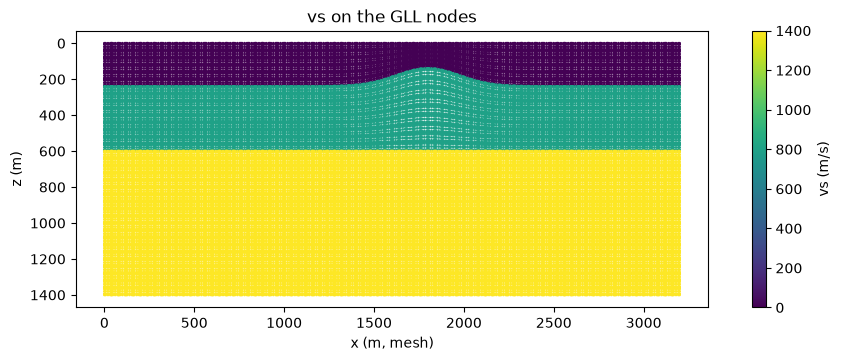

In [4]:
x = np.arange(shape[1]) * dh
seafloor = (240.0 - 100.0 * np.exp(-((x - 1400.0) / 250.0) ** 2)) / dh   # rows, top-down
solver = PropSEM(AcousticElasticSEM2D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=40, free_surface=True, f_dominant=f0,
                 interfaces=[seafloor, np.full(shape[1], z_layer / dh)], device=device)
models = [solver.layered_model(v) for v in ([1500.0, 2000.0, 2800.0],     # vp: water, sea floor, deep
                                            [0.0, 800.0, 1400.0],          # vs
                                            [1000.0, 1900.0, 2200.0])]     # rho
layer = solver.element_layer
print('model on the GLL nodes:', tuple(models[0].shape), '| elements per layer:',
      [int((layer == k).sum()) for k in range(3)], 'of', solver.mesh.n_elements)

mesh = solver.mesh
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
sc = ax.scatter(mesh.x_e.flatten().cpu(), mesh.z_e.flatten().cpu(), c=models[1].flatten().cpu(),
                s=1, cmap='viridis')
ax.invert_yaxis(); ax.set_aspect('equal')
ax.set_xlabel('x (m, mesh)'); ax.set_ylabel('z (m)'); ax.set_title('vs on the GLL nodes')
fig.colorbar(sc, ax=ax, label='vs (m/s)')
plt.show()

## 4. Hydrophones and ocean-bottom nodes

A source 20 m below the sea surface. The default `source_type=['chi']` is the
fluid potential's, and its wavelet is the pressure source, as on `PropTorch`.
Two receiver lines in one call: hydrophones 40 m deep and ocean-bottom nodes
just below the sea floor. Without a `receiver_type` the class records
`['p', 'vx', 'vz']` at every receiver, each in the medium it sits in: in the
water `p` is the pressure and `vx`, `vz` the particle velocity of the water; in
the rock `vx`, `vz` are the particle velocity of the solid and `p` its pressure,
`-kappa div u`. [Receivers · pressure, particle velocity, rotation, DAS](../47_sem_receivers/)
has more on them.

In [5]:
src = np.array([[120, 2]])                                    # x = 1200 m, 20 m deep
rx = np.arange(0, shape[1], 2)
hydrophones = np.stack([rx, np.full_like(rx, 4)], axis=1)
nodes = np.stack([rx, np.ceil(seafloor[rx]) + 1], axis=1)     # 10-20 m below the sea floor
receivers = np.concatenate([hydrophones, nodes])[None]        # (1, 2 * nrec, 2)

with torch.no_grad():
    seis = solver(wavelet, src, receivers, models=models)
print('record', tuple(seis.shape), ' components', solver.receiver_type)
nr = len(rx)
rec_hyd = seis[0, :, :nr].cpu().numpy()                       # (nt, nrec, [p, vx, vz])
rec_obn = seis[0, :, nr:].cpu().numpy()

record (1, 2800, 242, 3)  components ['p', 'vx', 'vz']


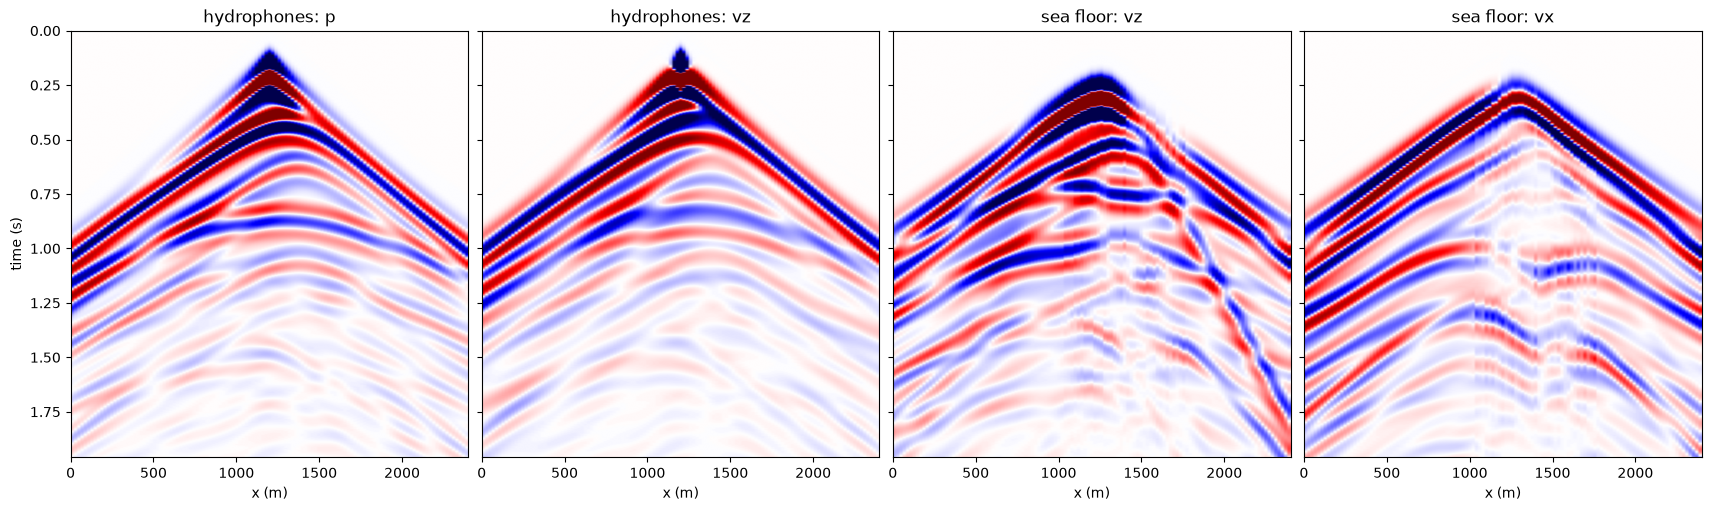

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 5), sharey=True, constrained_layout=True)
for ax, g, title in zip(axes, [rec_hyd[..., 0], rec_hyd[..., 2], rec_obn[..., 2], rec_obn[..., 1]],
                        ['hydrophones: p', 'hydrophones: vz', 'sea floor: vz', 'sea floor: vx']):
    v = np.percentile(np.abs(g), 98)
    ax.imshow(g, cmap='seismic', vmin=-v, vmax=v, aspect='auto',
              extent=[rx[0] * dh, rx[-1] * dh, nt * dt, 0])
    ax.set_title(title); ax.set_xlabel('x (m)')
axes[0].set_ylabel('time (s)')
plt.show()

The hydrophones record the direct wave, the sea-floor reflection and the
reverberations in the water layer, whose period is about
`2 x 240 m / 1500 m/s = 0.32 s` away from the seamount and shorter over it, on
`p` and `vz` alike. On the sea floor `vz` holds the same reverberations, and both
components carry slower, steeper events that start at the seamount and run
along the sea floor; the hydrophones above it do not record them.

## 5. The wavefield

Snapshots (eager) hold each domain's own field: the potential `chi` in the
water, the displacement `u_x`, `u_z` in the solid. The vertical displacement at
1.2 s, with the water blanked, where it is not defined:

sweep: torch.compile is compiling the AcousticElasticSEM2D step for a 101x241 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


snapshot fields ['chi', 'u_x', 'u_z'] (1, 3, 1, 1, 141, 321)


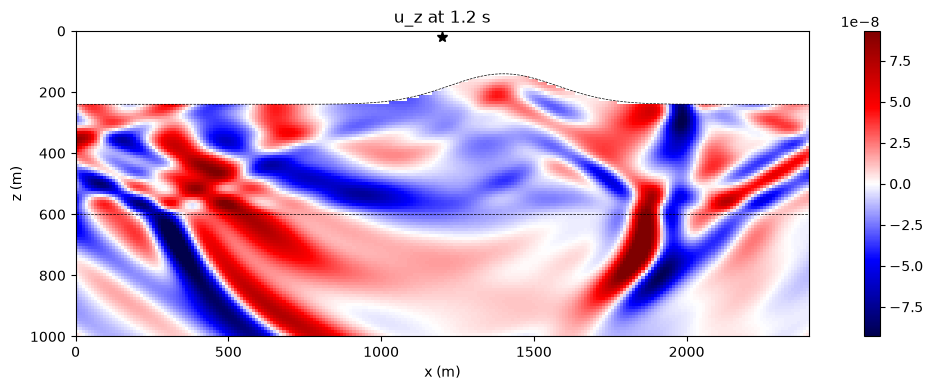

In [7]:
solver_e = PropSEM(AcousticElasticSEM2D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                   abcn=40, free_surface=True, f_dominant=f0,
                   interfaces=[seafloor, np.full(shape[1], z_layer / dh)], impl='eager',
                   device=device)
step = int(round(1.2 / dt))
with torch.no_grad():
    _, snaps = solver_e(wavelet, src, receivers, models=models,
                        return_wavefield=True, snapshot_times=[step])
print('snapshot fields', solver_e.snapshot_fields, tuple(snaps.shape))
uz = snaps[0, solver_e.snapshot_fields.index('u_z'), 0, 0].numpy()
uz = uz[:shape[0], 40:40 + shape[1]]                          # crop the C-PML
uz[np.arange(shape[0])[:, None] < seafloor[None, :]] = np.nan  # the water
v = np.nanpercentile(np.abs(uz[uz != 0]), 99)
plt.figure(figsize=(12, 4))
plt.imshow(uz, cmap='seismic', vmin=-v, vmax=v,
           extent=[0, (shape[1] - 1) * dh, (shape[0] - 1) * dh, 0])
plt.plot(x, seafloor * dh, 'k--', lw=0.5); plt.axhline(z_layer, color='k', lw=0.5, ls='--')
plt.plot(src[0, 0] * dh, src[0, 1] * dh, 'k*', ms=8)
plt.xlabel('x (m)'); plt.ylabel('z (m)'); plt.title('u_z at 1.2 s')
plt.colorbar(); plt.tight_layout(); plt.show()

## Summary

- `AcousticElasticSEM2D` takes `[vp, vs, rho]`; `vs = 0` marks the fluid, element by
  element, so a grid model whose sea floor crosses elements is refused.
- `interfaces=` makes the mesh follow the sea floor, of any shape, and the
  interfaces below it; `layered_model(values)` gives the model on the GLL nodes,
  one value per layer. Any `(n_elements, ngll, ngll)` tensor is taken as it is.
- Without `receiver_type` the class records `['p', 'vx', 'vz']` at every receiver,
  in the water and in the rock; it runs on `impl='c'`, with shot batching and
  boundary saving.

Next: [SEM in 3-D · acoustic, elastic, topography and Biot](../56_sem_3d/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="55_sem_fluid_solid.ipynb" download><code>55_sem_fluid_solid.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/55_sem_fluid_solid.ipynb">view on GitHub</a></p>